<a href="https://colab.research.google.com/github/NHnaz/Diabetes-Prediction/blob/main/Diabetes_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Abstract

This project focuses on predicting diabetes using machine learning techniques. The Pima Indians Diabetes Dataset was used, which contains 768 records with eight medical and personal features. Three issued algorithms were implemented: Logistic Regression, Decision Tree, and Random Forest. Before training, the dataset was explored and preprocessed by handling invalid zero values, replacing missing values with the median, and applying feature scaling where required. The models were evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC. Five-fold stratified cross-validation was also performed to compare their performance. Random Forest achieved the highest average cross-validation F1-score of 0.6811, while Logistic Regression achieved the highest test-set F1-score of 0.6496. The results show that all three models can identify diabetes cases with reasonably similar performance, although further improvements are needed for more reliable predictions.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(url, names=columns)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Dataset Source

The dataset used in this project is the Pima Indians Diabetes Dataset. It was obtained from a publicly available GitHub repository containing the original dataset in CSV format(for usability simplicity).

The dataset contains 768 patient records and nine columns, including eight input features and one target variable named Outcome.

The input features include Pregnancies, Glucose, Blood Pressure, Skin Thickness, Insulin, BMI, Diabetes Pedigree Function, and Age. The Outcome column represents whether a patient has diabetes or not, where 0 indicates a negative result and 1 indicates a positive result.

**Dataset Link:**  
https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv

In [ ]:
print("First 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nTarget Class Distribution:")
print(df["Outcome"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

First 5 Rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Target Class Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## Initial Data Exploration

The dataset was first examined to understand its structure, data types, statistical information, and target distribution. It contains 768 records and nine columns, with no initially recorded null values.

The target variable contains 500 negative cases and 268 positive cases. This shows that the dataset is somewhat imbalanced, as the number of non-diabetic records is higher than the number of diabetic records.

The statistical summary was also examined to understand the range and distribution of each feature. During this process, some medical measurements were found to contain zero values, which required further investigation during preprocessing.

In [ ]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for column in zero_columns:
    df[column] = df[column].replace(0, np.nan)

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)

Missing Values After Cleaning:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Dataset Shape: (768, 9)


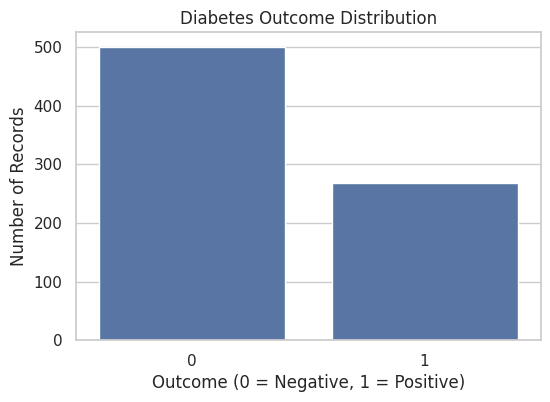

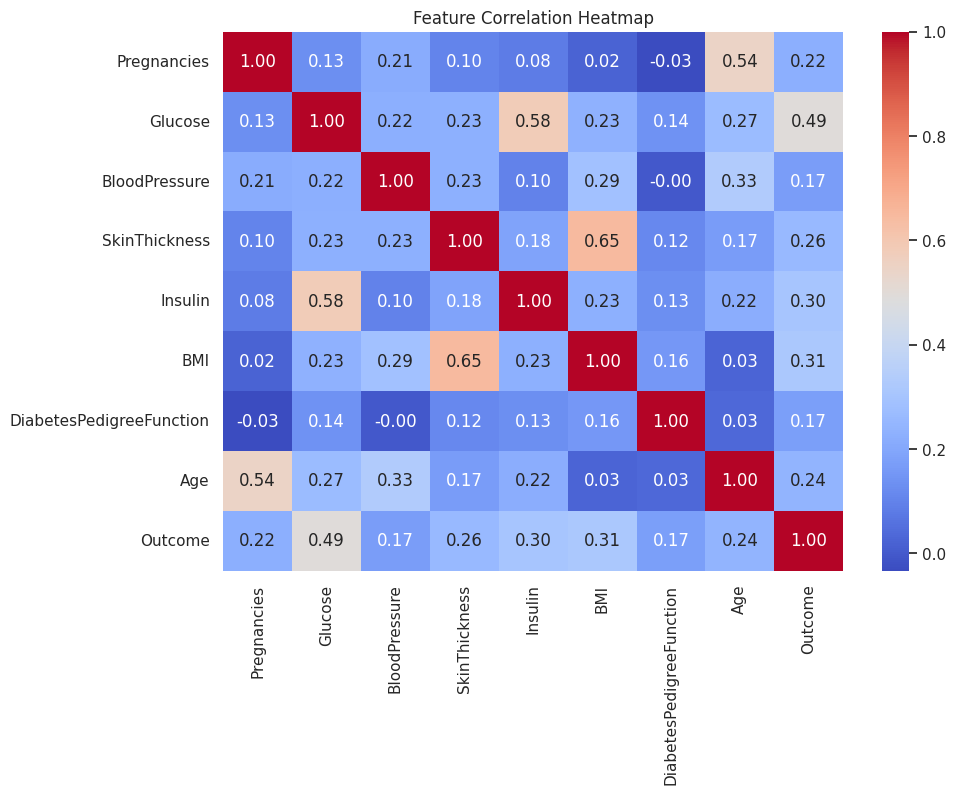

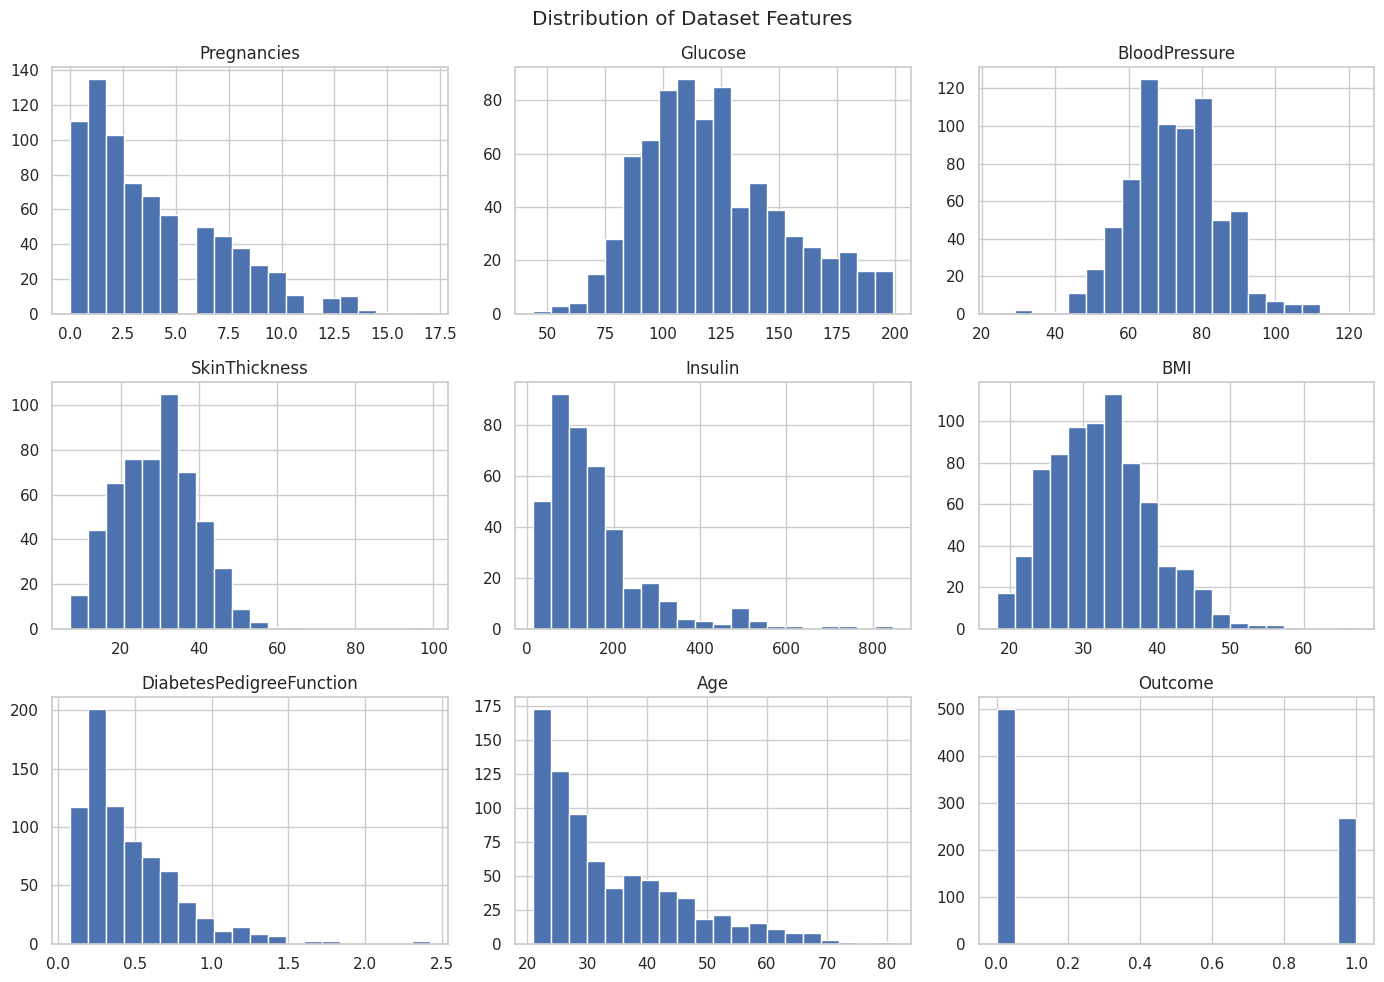

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Outcome")

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Records")
plt.show()


plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()


df.hist(figsize=(14, 10), bins=20)
plt.suptitle("Distribution of Dataset Features")
plt.tight_layout()
plt.show()

In [ ]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

Input Features Shape: (768, 8)
Target Shape: (768,)

Input Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (614, 8)
Testing Data: (154, 8)


## Model Development

Three machine learning classification algorithms were selected for this project to compare their performance in predicting diabetes.

**1. Logistic Regression**

Logistic Regression is a classification algorithm that estimates the probability of an outcome belonging to a particular class. It was used as a baseline model for predicting whether a patient has diabetes or not.

**2. Decision Tree Classifier**

Decision Tree is a tree-based algorithm that makes predictions by following a series of decisions based on input features. It divides the data into smaller groups until it reaches a final prediction.

**3. Random Forest Classifier**

Random Forest is an ensemble learning algorithm that combines multiple decision trees to produce a final prediction. It generally provides more stable results than using a single decision tree because it combines the predictions of several trees.

All three models were trained using the same training dataset to allow a fair comparison of their performance.

In [ ]:
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42
    ))
])

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

print("All Three Models Created Successfully!")

All Three Models Created Successfully!


In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1"
    )

    cv_results.append({
        "Model": name,
        "CV F1 Mean": scores.mean(),
        "CV F1 Std": scores.std()
    })

    print(name)
    print("F1 Scores:", scores)
    print("Average F1 Score:", round(scores.mean(), 4))
    print("-" * 40)

cv_df = pd.DataFrame(cv_results)

display(cv_df)

Logistic Regression
F1 Scores: [0.68965517 0.67368421 0.65060241 0.68131868 0.66666667]
Average F1 Score: 0.6724
----------------------------------------
Decision Tree
F1 Scores: [0.68518519 0.68       0.65263158 0.63551402 0.6407767 ]
Average F1 Score: 0.6588
----------------------------------------
Random Forest
F1 Scores: [0.70731707 0.67391304 0.69047619 0.65909091 0.6746988 ]
Average F1 Score: 0.6811
----------------------------------------


,Model,CV F1 Mean,CV F1 Std
0,Logistic Regression,0.672385,0.013319
1,Decision Tree,0.658821,0.020252
2,Random Forest,0.681099,0.016446


In [ ]:
results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

    trained_models[name] = model

    print("\nModel:", name)
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

results_df = pd.DataFrame(results)

display(results_df.round(4))


Model: Logistic Regression
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154


Model: Decision Tree
              precision    recall  f1-score   support

           0       0.79      0.79      0.79       100
           1       0.61      0.61      0.61        54

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154


Model: Random Forest
              precision    recall  f1-score   support

           0       0.81      0.77      0.79       100
           1       0.61      0.67      0.64        54

    accuracy                           0.73       154
   macro avg       0.71      0.72      0.71       154
we

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7338,0.6032,0.7037,0.6496,0.8126
1,Decision Tree,0.7273,0.6111,0.6111,0.6111,0.7706
2,Random Forest,0.7338,0.6102,0.6667,0.6372,0.8215


In [ ]:
best_model_name = (
    cv_df.sort_values(
        by="CV F1 Mean",
        ascending=False
    ).iloc[0]["Model"]
)

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print("\nCross Validation Results:")
display(cv_df.sort_values(
    by="CV F1 Mean",
    ascending=False
))

print("\nTest Set Performance:")
display(results_df.round(4))

Best Model: Random Forest

Cross Validation Results:


,Model,CV F1 Mean,CV F1 Std
2,Random Forest,0.681099,0.016446
0,Logistic Regression,0.672385,0.013319
1,Decision Tree,0.658821,0.020252



Test Set Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7338,0.6032,0.7037,0.6496,0.8126
1,Decision Tree,0.7273,0.6111,0.6111,0.6111,0.7706
2,Random Forest,0.7338,0.6102,0.6667,0.6372,0.8215


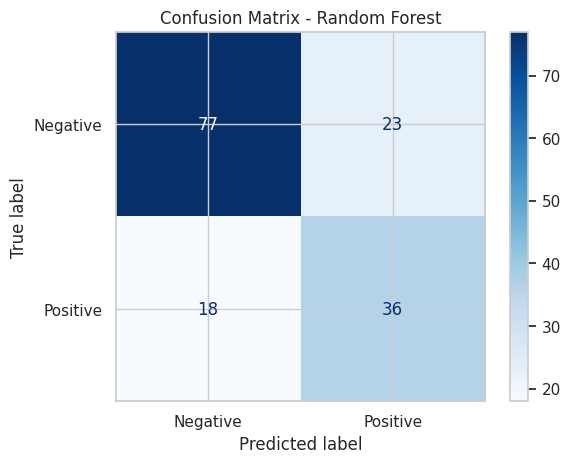

,Feature,Importance
1,Glucose,0.303023
5,BMI,0.172645
7,Age,0.126430
4,Insulin,0.104887
6,DiabetesPedigreeFunction,0.102116
3,SkinThickness,0.064938
2,BloodPressure,0.064478
0,Pregnancies,0.061484


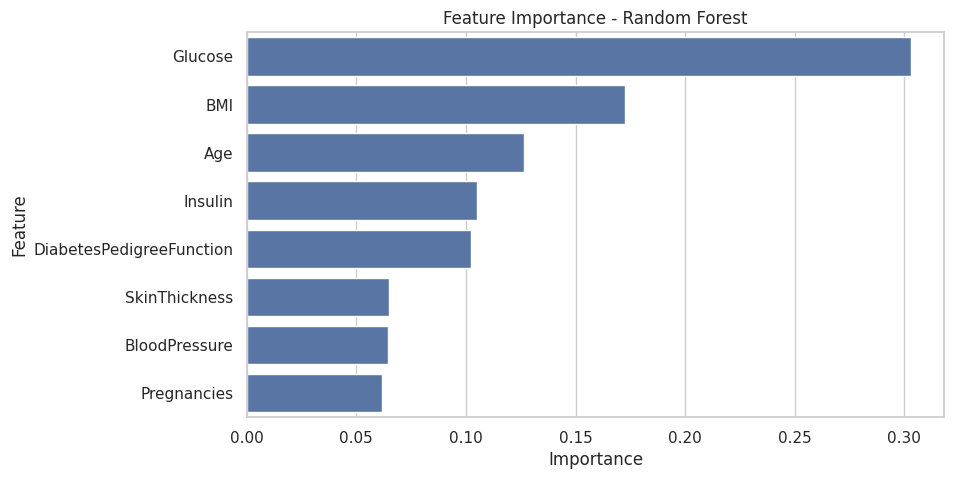

In [ ]:
best_predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - " + best_model_name)
plt.show()


classifier = best_model.named_steps["classifier"]

if hasattr(classifier, "feature_importances_"):
    importance = classifier.feature_importances_

elif hasattr(classifier, "coef_"):
    importance = np.abs(classifier.coef_[0])

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - " + best_model_name)
plt.show()

In [ ]:
new_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 25,
    "Insulin": 80,
    "BMI": 28.5,
    "DiabetesPedigreeFunction": 0.5,
    "Age": 30
}])

prediction = best_model.predict(new_patient)[0]
probability = best_model.predict_proba(new_patient)[0][1]

print("Selected Model:", best_model_name)

if prediction == 1:
    print("Model Output: Positive Class")
else:
    print("Model Output: Negative Class")

print("Model Probability:", round(probability * 100, 2), "%")

# Save the trained model
joblib.dump(best_model, "diabetes_prediction_model.pkl")

# Save evaluation results
results_df.to_csv("model_comparison.csv", index=False)

cv_df.to_csv("cross_validation_results.csv", index=False)

feature_importance.to_csv("feature_importance.csv", index=False)

print("\nProject Completed Successfully!")

print("Saved Files:")
print("1. diabetes_prediction_model.pkl")
print("2. model_comparison.csv")
print("3. cross_validation_results.csv")
print("4. feature_importance.csv")

Selected Model: Random Forest
Model Output: Negative Class
Model Probability: 25.17 %

Project Completed Successfully!
Saved Files:
1. diabetes_prediction_model.pkl
2. model_comparison.csv
3. cross_validation_results.csv
4. feature_importance.csv
